
# Clinical Laboratory Data Analysis & Quality Control

### Python | Pandas | NumPy | Matplotlib | Seaborn

## Project Overview

This project demonstrates the application of Python
to clinical laboratory data management, quality
assessment, and exploratory data analysis.

A synthetic dataset containing 200 laboratory records
was generated to simulate routine clinical data.

The workflow includes:

- Synthetic clinical dataset generation
- Identification of missing and invalid values
- Duplicate sample ID detection
- Data quality assessment and validation
- Exploratory data analysis (EDA)
- Statistical summaries and visualizations
- Correlation analysis

**Data disclaimer:** All records are entirely
synthetic. No real patient information is used.

**Author:** Biochemist | Clinical Laboratory
& Data Analysis



## 1. Library Imports & Configuration

The following libraries are used for data
manipulation, numerical operations, statistical
analysis, and visualization.


##2. Synthetic Dataset Generation

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
np.random.seed(42)

n = 200

df = pd.DataFrame({
    "Sample_ID": [f"LAB-{i:04d}" for i in range(1, n + 1)],
    "Age": np.random.randint(18, 85, n),
    "Glucose_mg_dL": np.random.normal(100, 25, n).round(1),
    "Creatinine_mg_dL": np.random.normal(0.95, 0.25, n).round(2),
    "Hemoglobin_g_dL": np.random.normal(13.5, 1.8, n).round(1),
    "WBC_10e3_uL": np.random.normal(7.2, 1.9, n).round(1),
    "Platelets_10e3_uL": np.random.normal(250, 60, n).round(0)
})

df.head()


,Sample_ID,Age,Glucose_mg_dL,Creatinine_mg_dL,Hemoglobin_g_dL,WBC_10e3_uL,Platelets_10e3_uL
0,LAB-0001,69,64.0,0.59,12.4,7.5,272.0
1,LAB-0002,32,129.8,0.74,14.6,6.6,205.0
2,LAB-0003,78,132.5,0.86,12.9,11.0,169.0
3,LAB-0004,38,78.3,1.06,12.9,7.1,231.0
4,LAB-0005,41,115.4,0.97,14.5,4.2,206.0


##3. Data Quality Assessment

In [ ]:

df_raw = df.copy()

df_raw.loc[5, "Glucose_mg_dL"] = np.nan
df_raw.loc[15, "Hemoglobin_g_dL"] = np.nan
df_raw.loc[25, "Creatinine_mg_dL"] = np.nan

df_raw.loc[35, "Glucose_mg_dL"] = -50
df_raw.loc[45, "Platelets_10e3_uL"] = -120

df_raw.loc[55, "Sample_ID"] = df_raw.loc[54, "Sample_ID"]

df_raw.loc[65, "Age"] = 250

df_raw.head(10)


,Sample_ID,Age,Glucose_mg_dL,Creatinine_mg_dL,Hemoglobin_g_dL,WBC_10e3_uL,Platelets_10e3_uL
0,LAB-0001,69,64.0,0.59,12.4,7.5,272.0
1,LAB-0002,32,129.8,0.74,14.6,6.6,205.0
2,LAB-0003,78,132.5,0.86,12.9,11.0,169.0
3,LAB-0004,38,78.3,1.06,12.9,7.1,231.0
4,LAB-0005,41,115.4,0.97,14.5,4.2,206.0
5,LAB-0006,20,NaN,1.20,15.4,6.4,249.0
6,LAB-0007,39,105.7,1.07,9.5,8.1,155.0
7,LAB-0008,70,121.2,0.96,14.1,8.2,284.0
8,LAB-0009,19,104.4,1.52,13.0,5.1,212.0
9,LAB-0010,47,69.6,1.05,15.2,9.0,310.0


##4. Data Validation

In [ ]:

missing_values = df_raw.isnull().sum()

duplicate_ids = df_raw["Sample_ID"].duplicated().sum()

lab_columns = [
    "Glucose_mg_dL",
    "Creatinine_mg_dL",
    "Hemoglobin_g_dL",
    "WBC_10e3_uL",
    "Platelets_10e3_uL"
]

negative_values = (df_raw[lab_columns] < 0).sum().sum()

invalid_ages = ((df_raw["Age"] < 0) | (df_raw["Age"] > 120)).sum()

print("DATA QUALITY REPORT")
print("-------------------")
print("Missing values:", missing_values.sum())
print("Duplicate IDs:", duplicate_ids)
print("Negative laboratory values:", negative_values)
print("Invalid ages:", invalid_ages)


DATA QUALITY REPORT
-------------------
Missing values: 3
Duplicate IDs: 1
Negative laboratory values: 2
Invalid ages: 1


##5. Data Quality Dashboard

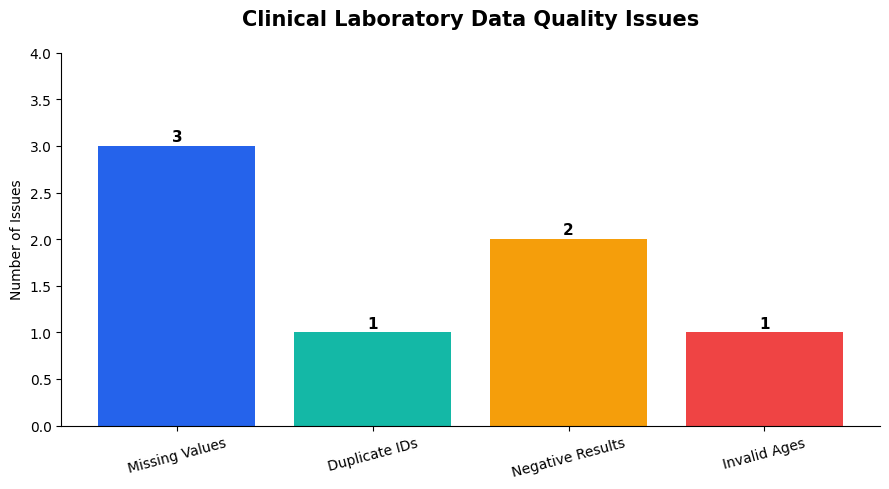

In [ ]:

issues = {
    "Missing Values": int(missing_values.sum()),
    "Duplicate IDs": int(duplicate_ids),
    "Negative Results": int(negative_values),
    "Invalid Ages": int(invalid_ages)
}

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    issues.keys(),
    issues.values(),
    color=["#2563EB", "#14B8A6", "#F59E0B", "#EF4444"]
)

for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.05,
        str(int(height)),
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

ax.set_title(
    "Clinical Laboratory Data Quality Issues",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_ylabel("Number of Issues")
ax.set_ylim(0, max(issues.values()) + 1)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    "data_quality_issues.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:

from google.colab import files

files.download("data_quality_issues.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Total records: 200
Flagged records: 8
Records without flags: 192


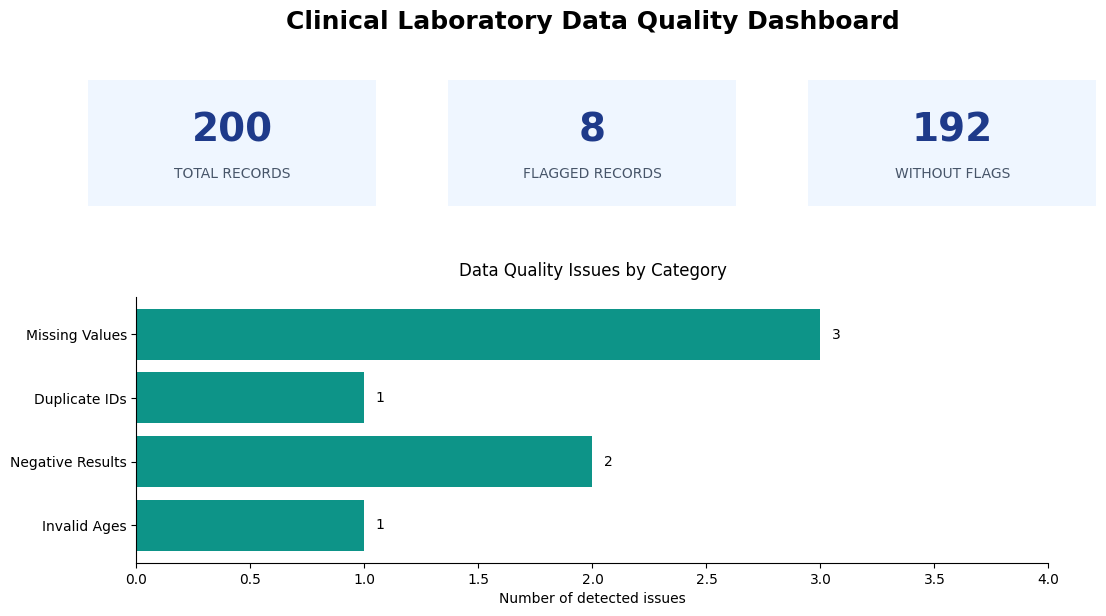

In [ ]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

missing_mask = df_raw.isna().any(axis=1)

duplicate_mask = df_raw["Sample_ID"].duplicated(
    keep=False
)

negative_mask = (df_raw[lab_columns] < 0).any(axis=1)

age_mask = (
    (df_raw["Age"] < 0) |
    (df_raw["Age"] > 120)
)

flagged_mask = (
    missing_mask |
    duplicate_mask |
    negative_mask |
    age_mask
)

total_records = len(df_raw)
flagged_records = int(flagged_mask.sum())
clean_records = total_records - flagged_records

print("Total records:", total_records)
print("Flagged records:", flagged_records)
print("Records without flags:", clean_records)


fig = plt.figure(figsize=(12, 7), facecolor="white")

fig.suptitle(
    "Clinical Laboratory Data Quality Dashboard",
    fontsize=18,
    fontweight="bold",
    y=0.96
)

metrics = [
    ("TOTAL RECORDS", total_records),
    ("FLAGGED RECORDS", flagged_records),
    ("WITHOUT FLAGS", clean_records)
]

positions = [0.08, 0.38, 0.68]

for (label, value), x in zip(metrics, positions):
    ax = fig.add_axes([x, 0.68, 0.24, 0.18])
    ax.axis("off")

    card = FancyBboxPatch(
        (0, 0), 1, 1,
        boxstyle="round,pad=0.03",
        facecolor="#EFF6FF",
        edgecolor="#CBD5E1"
    )
    ax.add_patch(card)

    ax.text(
        0.5, 0.60, str(value),
        ha="center", va="center",
        fontsize=28, fontweight="bold",
        color="#1E3A8A"
    )

    ax.text(
        0.5, 0.25, label,
        ha="center", va="center",
        fontsize=10, color="#475569"
    )

ax = fig.add_axes([0.12, 0.17, 0.76, 0.38])

categories = list(issues.keys())
values = list(issues.values())

bars = ax.barh(
    categories,
    values,
    color="#0D9488"
)

ax.invert_yaxis()
ax.set_xlabel("Number of detected issues")
ax.set_title("Data Quality Issues by Category", pad=15)

for bar in bars:
    ax.text(
        bar.get_width() + 0.05,
        bar.get_y() + bar.get_height()/2,
        str(int(bar.get_width())),
        va="center"
    )

ax.set_xlim(0, max(values) + 1)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.savefig(
    "clinical_data_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:

from google.colab import files
files.download("clinical_data_dashboard.png")


##6. Exploratory Data Analysis

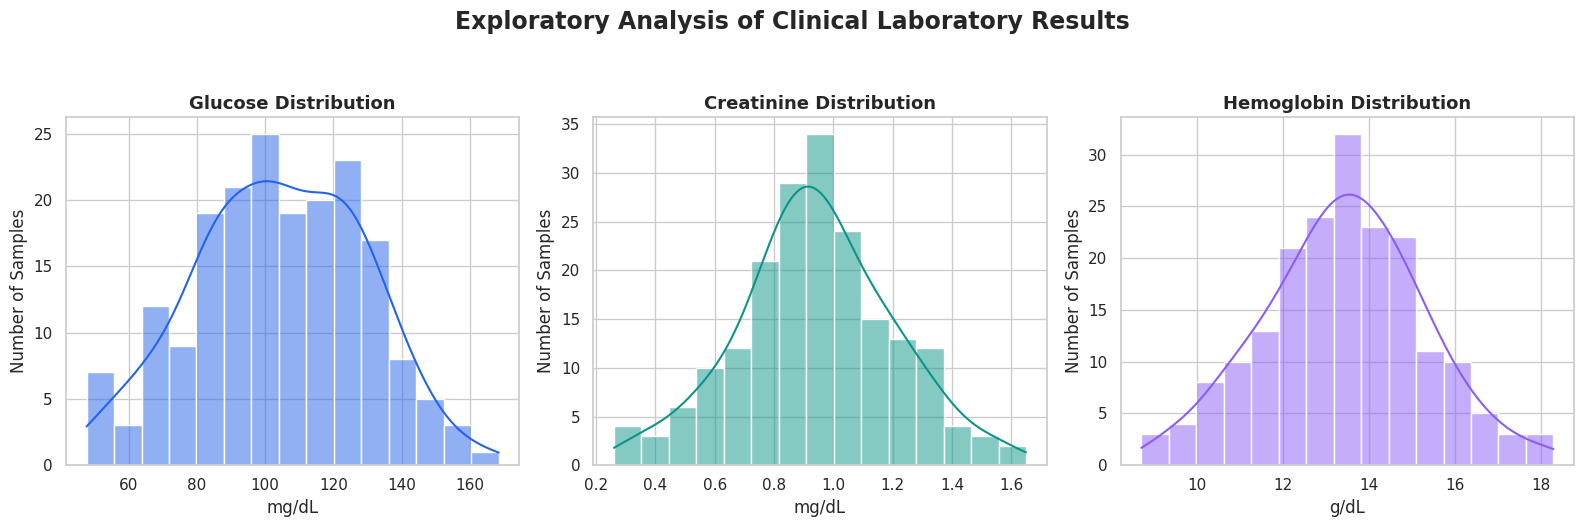

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns


df_clean = df_raw.loc[~flagged_mask].copy()

variables = {
    "Glucose_mg_dL": ("Glucose Distribution", "mg/dL"),
    "Creatinine_mg_dL": ("Creatinine Distribution", "mg/dL"),
    "Hemoglobin_g_dL": ("Hemoglobin Distribution", "g/dL")
}

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

colors = ["#2563EB", "#0D9488", "#8B5CF6"]

for ax, (column, (title, unit)), color in zip(
    axes, variables.items(), colors
):
    sns.histplot(
        data=df_clean,
        x=column,
        bins=15,
        kde=True,
        color=color,
        ax=ax
    )

    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel(unit)
    ax.set_ylabel("Number of Samples")

fig.suptitle(
    "Exploratory Analysis of Clinical Laboratory Results",
    fontsize=17,
    fontweight="bold",
    y=1.05
)

plt.tight_layout()

plt.savefig(
    "laboratory_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:


columns = [
    "Glucose_mg_dL",
    "Creatinine_mg_dL",
    "Hemoglobin_g_dL"
]

summary = df_clean[columns].agg(
    ["count", "mean", "median", "std", "min", "max"]
).round(2)

display(summary)


,Glucose_mg_dL,Creatinine_mg_dL,Hemoglobin_g_dL
count,192.00,192.00,192.00
mean,104.23,0.94,13.42
median,103.85,0.93,13.50
std,24.68,0.26,1.86
min,47.70,0.26,8.70
max,168.40,1.65,18.30


In [ ]:

from google.colab import files

files.download("laboratory_distributions.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

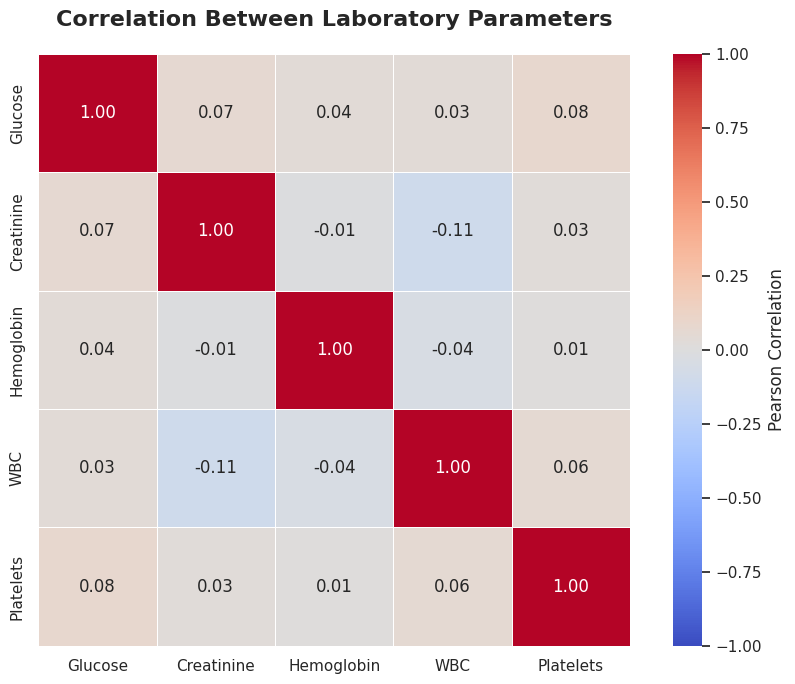

In [ ]:

import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

lab_variables = [
    "Glucose_mg_dL",
    "Creatinine_mg_dL",
    "Hemoglobin_g_dL",
    "WBC_10e3_uL",
    "Platelets_10e3_uL"
]


correlation_matrix = df_clean[lab_variables].corr(
    method="pearson"
)


labels = [
    "Glucose",
    "Creatinine",
    "Hemoglobin",
    "WBC",
    "Platelets"
]


plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    xticklabels=labels,
    yticklabels=labels,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Pearson Correlation"}
)

plt.title(
    "Correlation Between Laboratory Parameters",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.tight_layout()


plt.savefig(
    "laboratory_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:

from google.colab import files

files.download("laboratory_correlation_heatmap.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


## 8. Key Findings & Conclusions

### Data Quality Assessment

- Total simulated records: 200
- Intentionally introduced issues: 7
- Records flagged for review: 8
- Records passing the implemented checks: 192

The quality assessment identified missing values,
duplicate sample identifiers, negative laboratory
results, and an invalid age.

### Exploratory Data Analysis

Records passing the initial quality checks were
used to explore laboratory parameter distributions.

Descriptive statistics and correlation analysis
were performed using Python.

### Conclusions

This project demonstrates how Python can support
clinical laboratory data quality assessment,
automated validation checks, and visualization.

The workflow highlights the importance of
traceability, accurate data management, and
systematic quality control.

### Limitations

The dataset is synthetic and does not represent
real patient populations or clinical outcomes.

The implemented validation rules are illustrative
and do not replace laboratory-specific procedures
or clinical result validation.
